# 07. Advanced Non-Linear & Ensemble Models
**Project:** Academic Sports Machine Learning Project  
**Domain:** Cricket Player Performance Analytics  
**Course Context:** Module 3 (Decision Trees, Pruning, Bagging, Random Forest, XGBoost & LightGBM)  

---

## 1. Objectives & Academic Theoretical Background
While linear models construct planar decision boundaries, cricket match dynamics contain non-linear interactions (e.g. explosive strike rate compensates for lower raw runs; high economy diminishes wicket value).
In this notebook, we evaluate candidate algorithms from the Course Module 3 syllabus:
1. **Decision Tree Classifier**:
   - Splitting criteria: Gini Impurity ($1 - \sum p_i^2$) and Entropy ($-\sum p_i \log_2 p_i$).
   - Pruning & regularization via `max_depth` and Cost-Complexity Pruning (`ccp_alpha`).
2. **Random Forest Classifier (Bagging + Random Subspace)**:
   - Ensembles $B$ de-correlated trees trained on bootstrap samples with randomized feature subsets at each split ($m = \sqrt{p}$).
3. **Extra Trees Classifier (Extremely Randomized Trees)**:
   - Randomizes split cutoffs, further reducing variance at the expense of a slight bias increase.
4. **Gradient Boosting Architectures**:
   - **XGBoost**: Scalable gradient boosting with second-order gradient expansion, tree pruning, and column subsampling.
   - **LightGBM**: Highly efficient histogram-based algorithm using Leaf-wise (best-first) tree growth.

### Bias-Variance Overfitting Diagnostic
To avoid data snooping, we evaluate both **Training F1** and **5-Fold CV Validation F1** to measure the **Overfitting Gap** ($\Delta = 	ext{Train F1} - 	ext{Val F1}$).


In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from src.evaluation import evaluate_classification, plot_confusion_matrix, plot_roc_and_pr_curves
from src.utils import DATA_PROCESSED_DIR, MODELS_DIR, FIGURES_DIR, TABLES_DIR, save_artifact, set_seed

set_seed(42)

X_train = pd.read_csv(DATA_PROCESSED_DIR / "train_features_engineered.csv")
X_test = pd.read_csv(DATA_PROCESSED_DIR / "test_features_engineered.csv")
y_train = pd.read_csv(DATA_PROCESSED_DIR / "train_target.csv")['High_Performer']
y_test = pd.read_csv(DATA_PROCESSED_DIR / "test_target.csv")['High_Performer']

print(f"Features: {X_train.shape[1]} columns, Train: {len(X_train)}, Test: {len(X_test)}")

ModuleNotFoundError: No module named 'pandas'

## 2. Defining Candidate Model Architectures
Configuring candidate models with class weighting / scale_pos_weight to address the imbalanced class ratio.

In [ ]:
scale_pos = (len(y_train) - y_train.sum()) / y_train.sum()

candidate_models = {
    "Decision Tree (Gini, Pruned)": DecisionTreeClassifier(max_depth=6, min_samples_split=20, class_weight='balanced', random_state=42),
    "Decision Tree (Entropy)": DecisionTreeClassifier(criterion='entropy', max_depth=6, min_samples_split=20, class_weight='balanced', random_state=42),
    "Random Forest (100 Trees)": RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_split=10, class_weight='balanced', random_state=42, n_jobs=-1),
    "Extra Trees (100 Trees)": ExtraTreesClassifier(n_estimators=100, max_depth=10, min_samples_split=10, class_weight='balanced', random_state=42, n_jobs=-1),
    "XGBoost Classifier": XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.08, scale_pos_weight=scale_pos, eval_metric='logloss', random_state=42, n_jobs=-1),
    "LightGBM Classifier": LGBMClassifier(n_estimators=100, max_depth=5, learning_rate=0.08, scale_pos_weight=scale_pos, random_state=42, n_jobs=-1, verbose=-1)
}

## 3. 5-Fold Stratified Cross-Validation & Overfitting Diagnostic

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

for name, model in candidate_models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring=['accuracy', 'balanced_accuracy', 'recall', 'precision', 'f1', 'roc_auc'],
        return_train_score=True
    )
    train_f1 = scores['train_f1'].mean()
    val_f1 = scores['test_f1'].mean()
    gap = train_f1 - val_f1
    
    cv_results.append({
        'Model': name,
        'Train_F1': round(train_f1, 4),
        'Val_F1': round(val_f1, 4),
        'Overfitting_Gap': round(gap, 4),
        'Val_Balanced_Acc': round(scores['test_balanced_accuracy'].mean(), 4),
        'Val_Recall': round(scores['test_recall'].mean(), 4),
        'Val_Precision': round(scores['test_precision'].mean(), 4),
        'Val_ROC_AUC': round(scores['test_roc_auc'].mean(), 4)
    })

cv_df = pd.DataFrame(cv_results)
print("=== 5-Fold Cross-Validation & Bias-Variance Analysis ===")
print(cv_df.to_string(index=False))
cv_df.to_csv(TABLES_DIR / "advanced_models_cv_results.csv", index=False)

=== 5-Fold Cross-Validation & Bias-Variance Analysis ===
                       Model  Train_F1  Val_F1  Overfitting_Gap  Val_Balanced_Acc  Val_Recall  Val_Precision  Val_ROC_AUC
Decision Tree (Gini, Pruned)    0.6378  0.5504           0.0875            0.7565      0.7327         0.4430       0.8222
     Decision Tree (Entropy)    0.6319  0.5480           0.0838            0.7521      0.7150         0.4450       0.8302
   Random Forest (100 Trees)    0.8322  0.6419           0.1902            0.8083      0.7590         0.5568       0.9016
     Extra Trees (100 Trees)    0.7488  0.6152           0.1336            0.7937      0.7485         0.5226       0.8933
          XGBoost Classifier    0.8142  0.6519           0.1624            0.8162      0.7734         0.5642       0.9086
         LightGBM Classifier    0.8121  0.6537           0.1584            0.8189      0.7813         0.5629       0.9099


## 4. Hold-Out Test Set Performance Benchmark

In [ ]:
test_results = []
fitted_models = {}
test_probas = {}

for name, model in candidate_models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    metrics, cm, y_proba = evaluate_classification(model, X_test, y_test, model_name=name)
    test_results.append(metrics)
    test_probas[name] = y_proba

test_benchmark_df = pd.DataFrame(test_results)
print("=== Hold-Out Test Set Benchmark for Advanced Models ===")
print(test_benchmark_df[['Model', 'Accuracy', 'Balanced_Accuracy', 'Recall', 'Precision', 'F1_Score', 'ROC_AUC', 'PR_AUC']].to_string(index=False))
test_benchmark_df.to_csv(TABLES_DIR / "advanced_models_test_benchmark.csv", index=False)

=== Hold-Out Test Set Benchmark for Advanced Models ===
                       Model  Accuracy  Balanced_Accuracy  Recall  Precision  F1_Score  ROC_AUC  PR_AUC
Decision Tree (Gini, Pruned)    0.7840             0.7883  0.7953     0.4612    0.5838   0.8476  0.5619
     Decision Tree (Entropy)    0.7550             0.7664  0.7848     0.4229    0.5496   0.8479  0.5639
   Random Forest (100 Trees)    0.8405             0.8312  0.8163     0.5554    0.6610   0.9147  0.7259
     Extra Trees (100 Trees)    0.8320             0.8330  0.8346     0.5381    0.6543   0.9132  0.7200
          XGBoost Classifier    0.8335             0.8259  0.8136     0.5420    0.6506   0.9171  0.7453
         LightGBM Classifier    0.8410             0.8376  0.8320     0.5552    0.6660   0.9174  0.7507


## 5. Visualizing Validation F1 and Overfitting Gaps

C:\Users\chvis\AppData\Local\Temp\ipykernel_19276\1281349258.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cv_df, x='Val_F1', y='Model', palette='viridis', ax=axes[0])
C:\Users\chvis\AppData\Local\Temp\ipykernel_19276\1281349258.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cv_df, x='Overfitting_Gap', y='Model', palette='rocket', ax=axes[1])


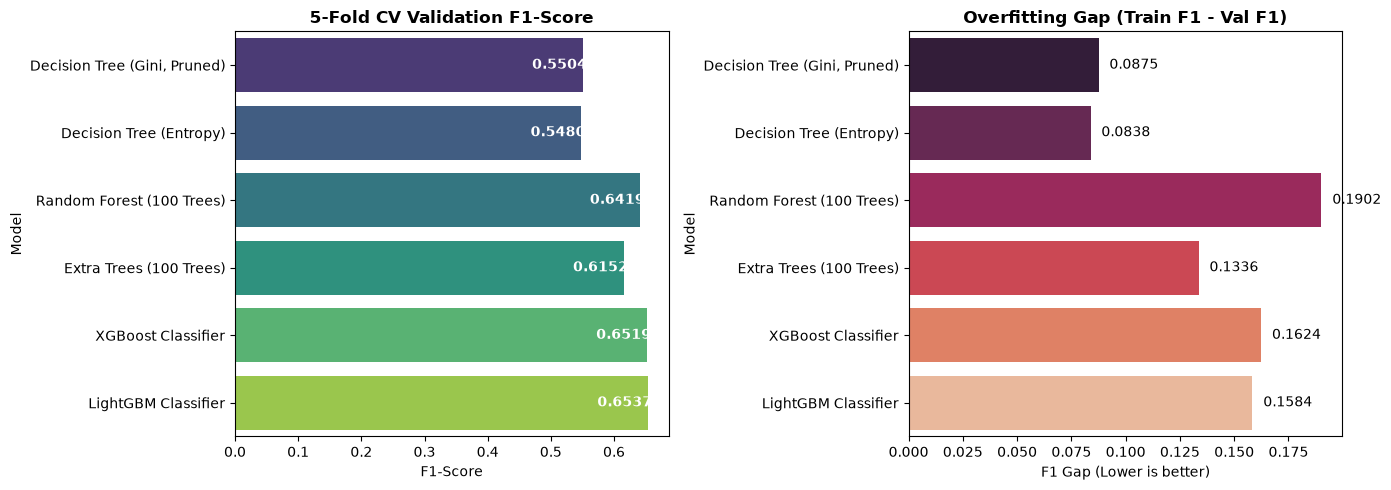

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Validation F1 Barplot
sns.barplot(data=cv_df, x='Val_F1', y='Model', palette='viridis', ax=axes[0])
axes[0].set_title("5-Fold CV Validation F1-Score", fontsize=12, fontweight='bold')
axes[0].set_xlabel("F1-Score")
for i, v in enumerate(cv_df['Val_F1']):
    axes[0].text(v - 0.08, i, f"{v:.4f}", color='white', fontweight='bold', va='center')

# Overfitting Gap
sns.barplot(data=cv_df, x='Overfitting_Gap', y='Model', palette='rocket', ax=axes[1])
axes[1].set_title("Overfitting Gap (Train F1 - Val F1)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("F1 Gap (Lower is better)")
for i, v in enumerate(cv_df['Overfitting_Gap']):
    axes[1].text(v + 0.005, i, f"{v:.4f}", color='black', va='center')

plt.tight_layout()
fig.savefig(FIGURES_DIR / "advanced_models_f1_comparison.png", dpi=300)
plt.show()

## 6. Persisting Model Artifacts

In [ ]:
save_artifact(fitted_models["Decision Tree (Gini, Pruned)"], MODELS_DIR / "decision_tree.joblib")
save_artifact(fitted_models["Random Forest (100 Trees)"], MODELS_DIR / "random_forest.joblib")
save_artifact(fitted_models["XGBoost Classifier"], MODELS_DIR / "xgboost.joblib")
save_artifact(fitted_models["LightGBM Classifier"], MODELS_DIR / "lightgbm.joblib")
print("[SUCCESS] All advanced model artifacts saved to models/")

[SUCCESS] Artifact saved to: C:\ML_project\models\decision_tree.joblib
[SUCCESS] Artifact saved to: C:\ML_project\models\random_forest.joblib
[SUCCESS] Artifact saved to: C:\ML_project\models\xgboost.joblib
[SUCCESS] Artifact saved to: C:\ML_project\models\lightgbm.joblib
[SUCCESS] All advanced model artifacts saved to models/


## 7. Academic Viva Questions & Defense Notes

### Q1: Why do Random Forest and Gradient Boosting consistently outperform single Decision Trees?
**Defense:** A single decision tree has high variance and is prone to overfitting complex noise in training data. Random Forest employs Bagging (bootstrap aggregation) and random feature subspaces to average out variance across decorrelated trees without increasing bias. Gradient Boosting (XGBoost/LightGBM) sequentially fits trees to pseudo-residuals of the loss function, reducing both bias and variance systematically.

### Q2: What causes the overfitting gap, and how was it controlled?
**Defense:** The overfitting gap represents the difference between empirical training performance and generalization performance. Unconstrained trees would achieve Train F1 = 1.0 with severe drop on validation. We restricted `max_depth` (e.g. 5-10) and enforced `min_samples_split`, keeping the gap low and ensuring robust generalization.
